<a href="https://colab.research.google.com/github/Kellia855/intro-to-ml_summative/blob/main/copd_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estimating the Likelihood of a Reported COPD Diagnosis in Adults 50+

**Goal.** COPD is often underdiagnosed because many people never get a breathing test. This project compares traditional machine learning and deep learning models that estimate how likely an adult aged 50 or older is to report a physician diagnosis of COPD, using self-reported demographic, lifestyle and health-history answers. It is intended as a **screening aid** to help prioritise people for clinical testing, not a diagnostic tool.

**What the model predicts.** The target `copd` is 1 if the respondent reports ever being told by a doctor that they have COPD, emphysema or chronic bronchitis (`CHCCOPD3`) and 0 otherwise. The model learns from about 269,000 respondents' answers and returns a probability for a new person. It does not diagnose COPD or forecast future disease, and undiagnosed cases appear as negatives in the data.

**Data.** CDC Behavioral Risk Factor Surveillance System (BRFSS) 2023; https://www.cdc.gov/brfss/annual_data/annual_2023.html


## Part 0. Setup

In [1]:
import os, json, time, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score,
                             f1_score, fbeta_score, balanced_accuracy_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import shutil, zipfile, os
zip_path = "/content/drive/MyDrive/ml_project/LLCP2023XPT.zip"
with zipfile.ZipFile(zip_path) as z:
    z.extractall("/content/data")
# the file inside has a trailing space in its name, so find it and rename it
for f in os.listdir("/content/data"):
    if f.strip().upper() == "LLCP2023.XPT":
        os.rename(f"/content/data/{f}", "/content/data/LLCP2023.XPT")

In [4]:
import numpy as np
import pandas as pd

# ---- Configuration -------------------------------------------------------
RAW_PATH  = "/content/data/LLCP2023.XPT"
OUT_PATH  = "/content/drive/MyDrive/ml_project/brfss_copd_50plus.parquet"
MODEL_DIR = "/content/drive/MyDrive/ml_project/models"

SEED, CHUNK = 42, 50_000
QUICK_RUN, QUICK_FRAC = True, 0.12
TUNE_N, SVM_N, LC_N, PI_N = 60_000, 15_000, 80_000, 15_000
N_ITER = {"logreg": 6, "rf": 6, "hgb": 12}
if QUICK_RUN:
    N_ITER = {"logreg": 3, "rf": 3, "hgb": 4}
SUFFIX = "_quick" if QUICK_RUN else ""
os.makedirs(MODEL_DIR, exist_ok=True)

USE_WANDB     = True
WANDB_PROJECT = "copd-2023"
WANDB_ENTITY  = None


### Experiment tracking with Weights & Biases

Every model run, experiment and tuning search is logged to a [Weights & Biases](https://wandb.ai) project so results can be compared and shared. Runs are organised into groups: `data`, `baselines`, `exp-missing-values`, `exp-imbalance`, `tuning` and `final`. On the first run a login prompt asks for your API key (get it at https://wandb.ai/authorize). Set `USE_WANDB = False` in the configuration to run without logging.

In [5]:
RUN = None
if USE_WANDB:
    try:
        import wandb
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wandb"])
        import wandb
    if os.environ.get("WANDB_MODE") != "offline":
        wandb.login()
else:
    wandb = None

def wb_start(name, group, config=None, job_type="train"):
    """Start a W&B run (no-op when USE_WANDB is False)."""
    global RUN
    if not USE_WANDB:
        return None
    RUN = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=name, group=group, job_type=job_type,
                     config={"seed": SEED, "quick_run": QUICK_RUN, **(config or {})})
    return RUN

def wb_end():
    global RUN
    if RUN is not None:
        wandb.finish()
        RUN = None

def wb_log(d):
    if RUN is not None:
        RUN.log(d)

def wb_summary(d):
    if RUN is not None:
        for k, v in d.items():
            RUN.summary[k] = v

def wb_table(name, frame):
    if RUN is not None:
        RUN.log({name: wandb.Table(dataframe=frame.reset_index())})

def show_fig(name):
    """Log the current matplotlib figure to W&B, then display it."""
    fig = plt.gcf()
    if RUN is not None:
        RUN.log({name: wandb.Image(fig)})
    plt.show()

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: k-kamikazi (k-kamikazi-african-leadership-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## Part 1. Data loading and preprocessing

This part loads the raw CDC BRFSS 2023 file (SAS Transport format) plus the 2023 codebook, defines the cohort, recodes survey codes, profiles missing values and saves the cleaned file. If the cleaned file already exists, you can skip this whole part.

### 1.1 Variables

Every name below was checked against the 2023 file. Variable meanings and value codes come from the 2023 codebook (`USCODE23_LLCP_021924.HTML`).

* **Target:** `CHCCOPD3` — ever told you have COPD, emphysema or chronic bronchitis (1 = yes, 2 = no, 7/9 = don't know/refused).
* **Cohort filter:** `_AGEG5YR` — 5-year age category; codes 7–13 are ages 50+, code 14 is don't know/refused.
* **Features:** grouped below. `POORHLTH` is deliberately left out (it is only asked conditionally and may partly reflect COPD symptoms), and race is excluded by default so that any use of it is a documented, justified experiment.

In [6]:
TARGET = "CHCCOPD3"
AGE    = "_AGEG5YR"

FEATURES = {
    "demographics": ["_AGE80", "SEXVAR", "MARITAL", "EMPLOY1", "EDUCA", "INCOME3", "VETERAN3", "_URBSTAT", "_STATE"],
    "smoking_substances": ["SMOKE100", "_SMOKER3", "SMOKDAY2", "LASTSMK2", "USENOW3", "ALCDAY4", "_DRNKWK2"],
    "health_status": ["GENHLTH", "PHYSHLTH", "MENTHLTH", "_BMI5", "_BMI5CAT", "EXERANY2", "DIFFWALK", "DIFFDRES", "DIFFALON"],
    "comorbidities": ["ASTHMA3", "CVDINFR4", "CVDCRHD4", "CVDSTRK3", "DIABETE4", "BPHIGH6", "TOLDHI3", "ADDEPEV3", "HAVARTH4", "CHCKDNY2"],
    "healthcare_use": ["CHECKUP1", "MEDCOST1", "FLUSHOT7", "PNEUVAC4"],
}
FEATURE_COLS = [c for cols in FEATURES.values() for c in cols]
KEEP = [TARGET, AGE] + FEATURE_COLS
print(len(FEATURE_COLS), "candidate features")

39 candidate features


### 1.2 Load the raw file in chunks

Only the columns we need are kept, and the **raw row count** is recorded while reading, because the assignment requires reporting the dataset size *before* any preprocessing.

In [7]:
reader = pd.read_sas(RAW_PATH, format="xport", chunksize=CHUNK, encoding="latin-1")
parts, n_raw, n_cols_raw = [], 0, None
for chunk in reader:
    n_cols_raw = chunk.shape[1]
    n_raw += len(chunk)
    parts.append(chunk[KEEP].copy())
raw = pd.concat(parts, ignore_index=True)
del parts

print(f"Raw file: {n_raw:,} rows x {n_cols_raw} columns")
print(f"Kept    : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw file: 433,323 rows x 350 columns
Kept    : 433,323 rows x 41 columns


,CHCCOPD3,_AGEG5YR,_AGE80,SEXVAR,MARITAL,EMPLOY1,EDUCA,INCOME3,VETERAN3,_URBSTAT,_STATE,SMOKE100,_SMOKER3,SMOKDAY2,LASTSMK2,...,DIFFALON,ASTHMA3,CVDINFR4,CVDCRHD4,CVDSTRK3,DIABETE4,BPHIGH6,TOLDHI3,ADDEPEV3,HAVARTH4,CHCKDNY2,CHECKUP1,MEDCOST1,FLUSHOT7,PNEUVAC4
0,2.0,13.0,80.0,2.0,1.0,7.0,5.0,99.0,2.0,1.0,1.0,2.0,4.0,NaN,NaN,...,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
1,2.0,13.0,80.0,2.0,2.0,7.0,5.0,99.0,2.0,1.0,1.0,2.0,4.0,NaN,NaN,...,2.0,2.0,2.0,2.0,2.0,3.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0
2,2.0,13.0,80.0,2.0,3.0,7.0,4.0,2.0,2.0,1.0,1.0,1.0,3.0,3.0,7.0,...,2.0,1.0,2.0,2.0,2.0,3.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0
3,2.0,12.0,78.0,2.0,1.0,7.0,5.0,99.0,2.0,1.0,1.0,2.0,4.0,NaN,NaN,...,2.0,2.0,2.0,2.0,2.0,3.0,3.0,2.0,1.0,1.0,2.0,3.0,2.0,1.0,1.0
4,2.0,12.0,76.0,2.0,3.0,8.0,5.0,7.0,2.0,1.0,1.0,2.0,4.0,NaN,NaN,...,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0


### 1.3 Define the cohort

1. Keep respondents with a valid target answer (1 = yes, 2 = no); drop "don't know", "refused" and blank.
2. Keep adults aged 50 and older (`_AGEG5YR` 7–13); drop code 14.

The funnel table documents how many rows survive each step.

In [8]:
funnel = [("Raw BRFSS 2023 records", len(raw))]

df = raw[raw[TARGET].isin([1, 2])].copy()
funnel.append(("Valid COPD answer (1 or 2)", len(df)))

df = df[df[AGE].between(7, 13)].copy()
funnel.append(("Adults 50+ (_AGEG5YR 7-13)", len(df)))

df["copd"] = (df[TARGET] == 1).astype(int)
funnel_df = pd.DataFrame(funnel, columns=["step", "rows"])
funnel_df["dropped"] = funnel_df["rows"].diff().fillna(0).astype(int)
display(funnel_df)

prev = df["copd"].mean()
print(f"COPD prevalence in cohort: {prev:.2%}  ({df['copd'].sum():,} positives, imbalance about 1:{(1-prev)/prev:.1f})")

,step,rows,dropped
0,Raw BRFSS 2023 records,433323,0
1,Valid COPD answer (1 or 2),431257,-2066
2,Adults 50+ (_AGEG5YR 7-13),269252,-162005


COPD prevalence in cohort: 10.56%  (28,432 positives, imbalance about 1:8.5)


### 1.4 Recode special values

BRFSS stores "don't know", "refused" and "none" as numeric codes that would be read as real values if left in place. Each rule below follows the 2023 codebook:

* Yes/no questions: 1 = yes, 2 = no, 7 and 9 = don't know/refused → missing.
* Days variables (`PHYSHLTH`, `MENTHLTH`): 88 = none → 0; 77 and 99 → missing.
* `ALCDAY4`: 101–199 = days per week, 201–299 = days per month, 888 = no drinks, 777/999 → missing. Converted to **drinking days per month**.
* `_DRNKWK2`: 99900 = missing; the stored value has two implied decimals, and a true zero is stored by SAS as a tiny denormal number (about 5e-79), which is snapped to exactly 0.
* `_BMI5`: two implied decimals (divide by 100).
* Ordinal/nominal categoricals: refusal codes → missing.
* Blank values on `SMOKDAY2`, `LASTSMK2` and `USENOW3` are *structural* (the question was skipped by design) and are kept as missing for now. Whether to impute, add indicator columns, or use an "not applicable" category is a modelling decision to document and compare.

In [9]:
def recode(d):
    d = d.copy()

    yes_no = ["SMOKE100", "EXERANY2", "DIFFWALK", "DIFFDRES", "DIFFALON", "VETERAN3",
              "ASTHMA3", "CVDINFR4", "CVDCRHD4", "CVDSTRK3", "TOLDHI3", "ADDEPEV3",
              "HAVARTH4", "CHCKDNY2", "MEDCOST1", "FLUSHOT7", "PNEUVAC4"]
    for c in yes_no:
        d[c] = d[c].map({1: 1, 2: 0})            # 7, 9, blank -> NaN

    d["is_female"] = (d["SEXVAR"] == 2).astype(int)

    # days variables
    for c in ["PHYSHLTH", "MENTHLTH"]:
        d[c] = d[c].replace({88: 0, 77: np.nan, 99: np.nan})

    # alcohol: drinking days per month
    a = d["ALCDAY4"]
    d["alc_days_month"] = np.select(
        [a == 888, a.between(101, 199), a.between(201, 299)],
        [0, (a - 100) * 30 / 7, a - 200],
        default=np.nan,
    )
    # SAS XPT stores a true 0 as a denormal (~5e-79); snap values that small to exactly 0
    drinks = d["_DRNKWK2"].replace(99900, np.nan) / 100
    d["alc_drinks_week"] = drinks.mask(drinks.abs() < 1e-6, 0)

    d["bmi"] = d["_BMI5"] / 100

    # categorical / ordinal codes with refusal values
    d["MARITAL"] = d["MARITAL"].replace({9: np.nan})
    d["EMPLOY1"] = d["EMPLOY1"].replace({9: np.nan})
    d["EDUCA"]   = d["EDUCA"].replace({9: np.nan})
    d["INCOME3"] = d["INCOME3"].replace({77: np.nan, 99: np.nan})
    d["GENHLTH"] = d["GENHLTH"].replace({7: np.nan, 9: np.nan})
    d["_SMOKER3"] = d["_SMOKER3"].replace({9: np.nan})
    d["SMOKDAY2"] = d["SMOKDAY2"].replace({7: np.nan, 9: np.nan})
    d["LASTSMK2"] = d["LASTSMK2"].replace({77: np.nan, 99: np.nan})
    d["USENOW3"]  = d["USENOW3"].replace({7: np.nan, 9: np.nan})
    d["DIABETE4"] = d["DIABETE4"].replace({7: np.nan, 9: np.nan})   # 1 yes, 2 yes (pregnancy only), 3 no, 4 prediabetes
    d["BPHIGH6"]  = d["BPHIGH6"].replace({7: np.nan, 9: np.nan})    # 1 yes, 2 yes (pregnancy only), 3 no, 4 borderline
    d["CHECKUP1"] = d["CHECKUP1"].replace({7: np.nan, 9: np.nan})   # 8 = never (kept as a real answer)

    d = d.drop(columns=["SEXVAR", "ALCDAY4", "_DRNKWK2", "_BMI5"])
    return d

clean = recode(df.drop(columns=[TARGET]))
print(clean.shape)
clean.head()

(269252, 41)


,_AGEG5YR,_AGE80,MARITAL,EMPLOY1,EDUCA,INCOME3,VETERAN3,_URBSTAT,_STATE,SMOKE100,_SMOKER3,SMOKDAY2,LASTSMK2,USENOW3,GENHLTH,...,DIABETE4,BPHIGH6,TOLDHI3,ADDEPEV3,HAVARTH4,CHCKDNY2,CHECKUP1,MEDCOST1,FLUSHOT7,PNEUVAC4,copd,is_female,alc_days_month,alc_drinks_week,bmi
0,13.0,80.0,1.0,7.0,5.0,NaN,0.0,1.0,1.0,0.0,4.0,NaN,NaN,3.0,2.0,...,1.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0,1,0.0,0.00,30.47
1,13.0,80.0,2.0,7.0,5.0,NaN,0.0,1.0,1.0,0.0,4.0,NaN,NaN,3.0,2.0,...,3.0,1.0,1.0,1.0,1.0,0.0,2.0,0.0,1.0,1.0,0,1,0.0,0.00,28.56
2,13.0,80.0,3.0,7.0,4.0,2.0,0.0,1.0,1.0,1.0,3.0,3.0,7.0,3.0,4.0,...,3.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0,1,0.0,0.00,22.31
3,12.0,78.0,1.0,7.0,5.0,NaN,0.0,1.0,1.0,0.0,4.0,NaN,NaN,3.0,2.0,...,3.0,3.0,0.0,1.0,1.0,0.0,3.0,0.0,1.0,1.0,0,1,0.0,0.00,27.44
4,12.0,76.0,3.0,8.0,5.0,7.0,0.0,1.0,1.0,0.0,4.0,NaN,NaN,2.0,4.0,...,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0,1,2.0,0.47,25.85


### 1.5 Sanity checks and missing-value profile

Quick checks that the recoding behaved as intended (value ranges and category counts), followed by the share of missing values per column. Columns with a lot of missingness need an explicit strategy in the modelling notebooks.

In [10]:
print(clean[["_AGE80", "bmi", "PHYSHLTH", "MENTHLTH", "alc_days_month", "alc_drinks_week"]].describe().round(2))
print()
for c in ["GENHLTH", "_SMOKER3", "DIABETE4", "BPHIGH6", "_AGEG5YR"]:
    print(c, clean[c].value_counts(dropna=False).sort_index().to_dict())

          _AGE80        bmi   PHYSHLTH   MENTHLTH  alc_days_month  alc_drinks_week
count  269252.00  248049.00  261616.00  264062.00       252517.00        251138.00
mean       67.12      28.50       5.16       3.39            5.14             2.54
std         9.18       6.24       9.60       7.68            8.69             7.32
min        50.00      12.02       0.00       0.00            0.00             0.00
25%        60.00      24.33       0.00       0.00            0.00             0.00
50%        67.00      27.44       0.00       0.00            0.00             0.00
75%        75.00      31.57       5.00       2.00            5.00             2.00
max        80.00      99.82      30.00      30.00           30.00           532.00

GENHLTH {1.0: 33173, 2.0: 86385, 3.0: 89949, 4.0: 42925, 5.0: 15981, nan: 839}
_SMOKER3 {1.0: 19931, 2.0: 6956, 3.0: 83088, 4.0: 146445, nan: 12832}
DIABETE4 {1.0: 51634, 2.0: 1184, 3.0: 207986, 4.0: 8068, nan: 380}
BPHIGH6 {1.0: 143903, 2.0: 860, 3.0:

In [11]:
miss = (clean.isna().mean() * 100).round(2).sort_values(ascending=False)
display(miss[miss > 0].to_frame("% missing"))

print("\nMissingness by COPD status (columns with the largest gap):")
gap = (clean.groupby("copd").apply(lambda g: g.isna().mean() * 100).T)
gap["diff"] = (gap[1] - gap[0]).abs()
display(gap.sort_values("diff", ascending=False).head(8).round(2))

,% missing
LASTSMK2,86.18
SMOKDAY2,59.16
INCOME3,20.37
PNEUVAC4,9.81
_BMI5CAT,7.87
bmi,7.87
alc_drinks_week,6.73
FLUSHOT7,6.35
alc_days_month,6.22
TOLDHI3,5.88



Missingness by COPD status (columns with the largest gap):


copd,0,1,diff
SMOKDAY2,62.97,26.87,36.10
LASTSMK2,87.03,78.97,8.06
CVDCRHD4,1.01,2.85,1.84
PNEUVAC4,9.99,8.23,1.76
PHYSHLTH,2.66,4.30,1.64
TOLDHI3,5.75,6.96,1.21
MENTHLTH,1.82,2.85,1.03
_BMI5CAT,7.98,7.02,0.96


### 1.6 Save the cleaned cohort

The saved Parquet file loads in seconds and keeps this notebook independent from the 1.2 GB raw file. Modelling notebooks should apply the stratified train/validation/test split themselves, with `SEED` fixed, and fit all imputers, scalers and encoders on the training set only to avoid leakage.

In [12]:
clean.to_parquet(OUT_PATH, index=False)
print("Saved", OUT_PATH, clean.shape)

Saved /content/drive/MyDrive/ml_project/brfss_copd_50plus.parquet (269252, 41)


In [13]:
import pandas as pd
df = pd.read_parquet("/content/drive/MyDrive/ml_project/brfss_copd_50plus.parquet")
print(df.shape)
print(df["copd"].value_counts())

(269252, 41)
copd
0    240820
1     28432
Name: count, dtype: int64


## Part 2. Traditional machine learning(Scikit-learn)
This part trains and compares traditional models on the cleaned cohort from Part 1


### 2.1 Load the cleaned cohort

Part 1 produced one row per respondent aged 50+ with a valid COPD answer. The column `copd` is the target (1 = reports a COPD diagnosis). Two columns, `_AGEG5YR` and `_BMI5CAT`, duplicate `_AGE80` and `bmi`, so they are kept only as *metadata* for the subgroup analysis and are not used as features.

`CHECKUP1` uses code 8 for "never"; it is recoded to 5 so the variable is a single ordinal scale (1 = within the past year ... 5 = never).

In [14]:
df = pd.read_parquet(OUT_PATH)
if QUICK_RUN:
    df = (df.groupby("copd", group_keys=False)
            .sample(frac=QUICK_FRAC, random_state=SEED).sort_index())
df = df.reset_index(drop=True)
df["CHECKUP1"] = df["CHECKUP1"].replace(8, 5)

print(df.shape, f"| positive rate {df['copd'].mean():.2%}")

(32310, 41) | positive rate 10.56%


### 2.2 Feature groups

Every feature is assigned to a type so that each gets the right treatment:

* **Continuous** (`bmi`, drinks, days of poor health): clipped at the 1st/99th percentile (learned on training data), median-imputed, scaled.
* **Binary and ordinal** (yes/no answers coded 0/1, health and income scales): median-imputed (the mode for binary), scaled.
* **Nominal** (marital status, employment, diabetes status, smoker status, state, ...): one-hot encoded; rare categories grouped.

In [15]:
TARGET = "copd"
CONT    = ["bmi", "alc_days_month", "alc_drinks_week", "PHYSHLTH", "MENTHLTH", "_AGE80"]
BINARY  = ["is_female", "SMOKE100", "EXERANY2", "DIFFWALK", "DIFFDRES", "DIFFALON", "VETERAN3", "ASTHMA3",
           "CVDINFR4", "CVDCRHD4", "CVDSTRK3", "TOLDHI3", "ADDEPEV3", "HAVARTH4", "CHCKDNY2",
           "MEDCOST1", "FLUSHOT7", "PNEUVAC4"]
ORDINAL = ["GENHLTH", "EDUCA", "INCOME3", "CHECKUP1"]
NOMINAL = ["MARITAL", "EMPLOY1", "DIABETE4", "BPHIGH6", "_SMOKER3", "SMOKDAY2", "LASTSMK2", "USENOW3",
           "_URBSTAT", "_STATE"]
META    = ["_AGEG5YR", "_BMI5CAT"]
ALL_FEATURES = CONT + BINARY + ORDINAL + NOMINAL

missing = [c for c in ALL_FEATURES + META if c not in df.columns]
assert not missing, missing
X, y = df[ALL_FEATURES], df[TARGET].values
print(len(ALL_FEATURES), "features")

38 features


### 2.3 Train / validation / test split

A stratified 70 / 15 / 15 split keeps the 10.6% positive rate in all three parts. The **training set** fits models and preprocessing, the **validation set** is used for model selection and for choosing decision thresholds, and the **test set** is touched only for the final evaluation. The row indices are saved at the end so the deep learning part (Part 3) can reuse the identical split.

BRFSS respondents are independent survey participants (there is no patient identifier and no repeated measurement), so a random split is appropriate.

In [16]:
idx = np.arange(len(df))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)

X_train, y_train = X.iloc[idx_train], y[idx_train]
X_val,   y_val   = X.iloc[idx_val],   y[idx_val]
X_test,  y_test  = X.iloc[idx_test],  y[idx_test]

pd.DataFrame({"rows": [len(idx_train), len(idx_val), len(idx_test)],
              "positives": [y_train.sum(), y_val.sum(), y_test.sum()],
              "positive rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(4)

,rows,positives,positive rate
train,22617,2388,0.1056
validation,4846,512,0.1057
test,4847,512,0.1056


### 2.4 Preprocessing pipelines

All preprocessing lives **inside** scikit-learn pipelines, so imputers, scalers, encoders and the clipping limits are fitted on training rows only (also inside each cross-validation fold). This prevents information from the validation or test data leaking into training.

`make_preprocessor` supports two missing-value strategies, compared in section 8:

* `"simple"`: median (numeric) or most-frequent (categorical) imputation.
* `"indicator"`: the same numeric imputation **plus missing-indicator columns**, and an explicit "missing / not asked" category for nominal variables. This matters here because some blanks are structural (for example `SMOKDAY2` is blank for people who never smoked), so *being missing carries information*.

In [17]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to the [lower, upper] quantiles learned on the training data."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

def make_preprocessor(cols, strategy="indicator", scale=True):
    ind  = strategy == "indicator"
    cont = [c for c in CONT if c in cols]
    other = [c for c in BINARY + ORDINAL if c in cols]
    nom  = [c for c in NOMINAL if c in cols]

    def num_steps(winsor):
        steps = [("winsor", Winsorizer())] if winsor else []
        steps.append(("impute", SimpleImputer(strategy="median", add_indicator=ind)))
        if scale:
            steps.append(("scale", StandardScaler()))
        return Pipeline(steps)

    nom_imp = SimpleImputer(strategy="constant", fill_value=-1) if ind else SimpleImputer(strategy="most_frequent")
    nom_pipe = Pipeline([("impute", nom_imp),
                         ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=200,
                                               sparse_output=False, dtype=np.float32))])
    parts = []
    if cont:  parts.append(("cont", num_steps(True), cont))
    if other: parts.append(("other", num_steps(False), other))
    if nom:   parts.append(("nom", nom_pipe, nom))
    return ColumnTransformer(parts, remainder="drop")

DEFAULTS = {
    "logreg": dict(C=1.0, class_weight="balanced"),
    "rf":     dict(n_estimators=150, max_depth=None, min_samples_leaf=5, max_features="sqrt",
                   class_weight="balanced_subsample"),
    "hgb":    dict(learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=50, l2_regularization=1.0,
                   class_weight="balanced"),
    "svm":    dict(C=1.0, class_weight="balanced"),
}

def build(name, cols=ALL_FEATURES, strategy="indicator", **params):
    p = {**DEFAULTS[name], **params}
    if name == "logreg":
        clf, scale = LogisticRegression(max_iter=2000, **p), True
    elif name == "rf":
        clf, scale = RandomForestClassifier(n_jobs=-1, random_state=SEED, **p), False
    elif name == "hgb":
        clf, scale = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                                    n_iter_no_change=20, random_state=SEED, **p), False
    elif name == "svm":
        clf, scale = SVC(kernel="rbf", gamma="scale", **p), True
    return Pipeline([("prep", make_preprocessor(cols, strategy, scale)), ("clf", clf)])

print(build("logreg"))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cont',
                                                  Pipeline(steps=[('winsor',
                                                                   Winsorizer()),
                                                                  ('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['bmi', 'alc_days_month',
                                                   'alc_drinks_week',
                                                   'PHYSHLTH', 'MENTHLTH',
                                                   '_AGE80']),
                              

### 2.5 Evaluation helpers

For each model we report threshold-free metrics (ROC-AUC, PR-AUC) and, at a decision threshold, recall, precision, F1, F2 and balanced accuracy. **Thresholds are always chosen on the validation set** (the one that maximises F2) and then applied unchanged to the test set.

In [18]:
def get_scores(model, X_):
    return model.predict_proba(X_)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_)

def best_threshold(y_true, s, beta=2.0):
    prec, rec, thr = precision_recall_curve(y_true, s)
    f = (1 + beta**2) * prec * rec / (beta**2 * prec + rec + 1e-12)
    return thr[np.nanargmax(f[:-1])]

def metrics(y_true, s, thr):
    pred = (s >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, s), "PR-AUC": average_precision_score(y_true, s),
            "threshold": thr, "recall": recall_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred), "F2": fbeta_score(y_true, pred, beta=2),
            "balanced acc": balanced_accuracy_score(y_true, pred),
            "flagged %": pred.mean() * 100}

def stratified_sample(X_, y_, n, seed=SEED):
    if n >= len(X_):
        return X_, y_
    sel, _ = train_test_split(np.arange(len(X_)), train_size=n, stratify=y_, random_state=seed)
    return X_.iloc[sel], y_[sel]

### 2.6 Baseline and candidate models

Logistic Regression is the **baseline**: a simple, interpretable linear model that every other model has to beat to justify its extra complexity. Random Forest, Gradient Boosting and an RBF-kernel SVM are the **candidate models**. All four are trained once with sensible default settings and class weighting for the imbalance, then compared on the validation set. The best candidates are tuned in section 2.9.

Each model has its own cell below. They share one helper that fits the model, picks its F2-optimal threshold on the validation set, records the metrics and logs the run to Weights & Biases (group `initial-models`).

In [19]:
results, val_scores, fitted = [], {}, {}

def run_model(label, model, X_fit, y_fit, role="candidate"):
    wb_start(label, "initial-models", {"model": label, "role": role,
                                       "train_rows": len(X_fit), "n_features": len(ALL_FEATURES)})
    t0 = time.time()
    model.fit(X_fit, y_fit)
    s = get_scores(model, X_val)
    thr = best_threshold(y_val, s)
    res = {"model": label, "role": role, **metrics(y_val, s, thr), "fit time (s)": time.time() - t0}
    results.append(res); val_scores[label] = s; fitted[label] = model
    print(f"{label:28s} PR-AUC {res['PR-AUC']:.3f}  ROC-AUC {res['ROC-AUC']:.3f}  ({res['fit time (s)']:.0f}s)")
    wb_log({f"val/{k}": v for k, v in res.items() if k not in ("model", "role")}); wb_end()

#### Baseline: Logistic Regression
A linear model that estimates the probability of COPD as a weighted sum of the features. It is fast, hard to overfit and easy to interpret, which makes it the standard reference point. `class_weight="balanced"` gives the rare positive class more weight, and `C=1.0` applies moderate regularisation.

In [20]:
run_model("Logistic Regression", build("logreg"), X_train, y_train, role="baseline")

Logistic Regression          PR-AUC 0.470  ROC-AUC 0.856  (1s)


val/F1,▁
val/F2,▁
val/PR-AUC,▁
val/ROC-AUC,▁
val/balanced acc,▁
val/fit time (s),▁
val/flagged %,▁
val/precision,▁
val/recall,▁
val/threshold,▁
val/F1,0.4052


#### Candidate: Random Forest
Many decision trees trained on random subsets of rows and features, with their votes averaged. It captures non-linear effects and interactions (for example, smoking combined with asthma) that a linear model cannot. `min_samples_leaf=5` and `class_weight="balanced_subsample"` limit overfitting and handle the imbalance.

In [21]:
run_model("Random Forest", build("rf"), X_train, y_train)

Random Forest                PR-AUC 0.446  ROC-AUC 0.848  (5s)


val/F1,▁
val/F2,▁
val/PR-AUC,▁
val/ROC-AUC,▁
val/balanced acc,▁
val/fit time (s),▁
val/flagged %,▁
val/precision,▁
val/recall,▁
val/threshold,▁
val/F1,0.41726


#### Candidate: Histogram Gradient Boosting
Trees built one after another, each correcting the errors of the previous ones. It is usually the strongest traditional method on tabular data and is fast on large datasets. Early stopping and L2 regularisation limit overfitting, and class weights handle the imbalance.

In [22]:
run_model("Hist Gradient Boosting", build("hgb"), X_train, y_train)

Hist Gradient Boosting       PR-AUC 0.476  ROC-AUC 0.853  (3s)


val/F1,▁
val/F2,▁
val/PR-AUC,▁
val/ROC-AUC,▁
val/balanced acc,▁
val/fit time (s),▁
val/flagged %,▁
val/precision,▁
val/recall,▁
val/threshold,▁
val/F1,0.43108


#### Candidate: Support Vector Machine (RBF kernel)
Finds a boundary that separates the classes with the widest margin, using a non-linear kernel. Training time grows quickly with the number of rows, so it is trained on a stratified subsample (`SVM_N` rows) instead of the full training set. This is a documented compromise and should be stated in the report.

In [23]:
Xs, ys = stratified_sample(X_train, y_train, SVM_N)
run_model("SVM (RBF, subsample)", build("svm"), Xs, ys)

SVM (RBF, subsample)         PR-AUC 0.382  ROC-AUC 0.834  (27s)


val/F1,▁
val/F2,▁
val/PR-AUC,▁
val/ROC-AUC,▁
val/balanced acc,▁
val/fit time (s),▁
val/flagged %,▁
val/precision,▁
val/recall,▁
val/threshold,▁
val/F1,0.37461


In [24]:
initial_df = pd.DataFrame(results).set_index("model").round(3).sort_values("PR-AUC", ascending=False)
initial_df

,role,ROC-AUC,PR-AUC,threshold,recall,precision,F1,F2,balanced acc,flagged %,fit time (s)
model,,,,,,,,,,,
Hist Gradient Boosting,candidate,0.853,0.476,0.505,0.742,0.304,0.431,0.576,0.771,25.815,3.127
Logistic Regression,baseline,0.856,0.470,0.463,0.791,0.272,0.405,0.573,0.771,30.685,1.220
Random Forest,candidate,0.848,0.446,0.360,0.746,0.290,0.417,0.567,0.765,27.218,4.745
"SVM (RBF, subsample)",candidate,0.834,0.382,-0.498,0.812,0.243,0.375,0.554,0.757,35.266,27.203


**Your interpretation (write this in your own words for the report):** How much does each candidate improve on the Logistic Regression baseline in PR-AUC and ROC-AUC? Is the gain large enough to justify the added complexity and training time? What do the differences between linear and tree-based models suggest about interactions in the data?

### 2.7 Experiment A: missing-value strategy

The same two models are trained with `"simple"` imputation and with `"indicator"` handling (missing-indicator columns and an explicit "missing/not asked" category), and compared on the validation set. If the indicator version is better, the *missingness pattern itself* is informative.

In [25]:
rows = []
for name in ["logreg", "hgb"]:
    for strat in ["simple", "indicator"]:
        wb_start(f"{name}-{strat}", "exp-missing-values", {"model": name, "strategy": strat})
        m = build(name, strategy=strat).fit(X_train, y_train)
        s = get_scores(m, X_val)
        rows.append({"model": name, "strategy": strat,
                     "ROC-AUC": roc_auc_score(y_val, s), "PR-AUC": average_precision_score(y_val, s)})
        wb_log({"val/ROC-AUC": rows[-1]["ROC-AUC"], "val/PR-AUC": rows[-1]["PR-AUC"]}); wb_end()
missing_df = pd.DataFrame(rows).round(4)
missing_df

val/PR-AUC,▁
val/ROC-AUC,▁
val/PR-AUC,0.46641
val/ROC-AUC,0.85319


val/PR-AUC,▁
val/ROC-AUC,▁
val/PR-AUC,0.46988
val/ROC-AUC,0.85595


val/PR-AUC,▁
val/ROC-AUC,▁
val/PR-AUC,0.46756
val/ROC-AUC,0.84869


val/PR-AUC,▁
val/ROC-AUC,▁
val/PR-AUC,0.47611
val/ROC-AUC,0.85319


,model,strategy,ROC-AUC,PR-AUC
0,logreg,simple,0.8532,0.4664
1,logreg,indicator,0.8560,0.4699
2,hgb,simple,0.8487,0.4676
3,hgb,indicator,0.8532,0.4761


**Your interpretation:** Does adding missing-indicators / an explicit "not asked" category help? Relate this to the structural missingness in `SMOKDAY2` and `LASTSMK2` found in Part 1.

### 2.8 Experiment B: handling class imbalance

Gradient boosting is trained without weights and with balanced class weights. Threshold-free metrics change little, but the *default 0.5 threshold* behaves very differently, which is why the threshold is tuned on the validation set.

In [26]:
rows = []
for cw in [None, "balanced"]:
    wb_start(f"hgb-class_weight-{cw}", "exp-imbalance", {"model": "hgb", "class_weight": str(cw)})
    m = build("hgb", class_weight=cw).fit(X_train, y_train)
    s = get_scores(m, X_val)
    thr = best_threshold(y_val, s)
    at05, atopt = metrics(y_val, s, 0.5), metrics(y_val, s, thr)
    rows.append({"class_weight": str(cw), "ROC-AUC": at05["ROC-AUC"], "PR-AUC": at05["PR-AUC"],
                 "recall@0.5": at05["recall"], "precision@0.5": at05["precision"],
                 "tuned thr": thr, "recall@tuned": atopt["recall"], "precision@tuned": atopt["precision"]})
    wb_log({k: v for k, v in rows[-1].items() if k != "class_weight"}); wb_end()
pd.DataFrame(rows).round(3)

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


PR-AUC,▁
ROC-AUC,▁
precision@0.5,▁
precision@tuned,▁
recall@0.5,▁
recall@tuned,▁
tuned thr,▁
PR-AUC,0.46494
ROC-AUC,0.85292
precision@0.5,0.63594
precision@tuned,0.31293


PR-AUC,▁
ROC-AUC,▁
precision@0.5,▁
precision@tuned,▁
recall@0.5,▁
recall@tuned,▁
tuned thr,▁
PR-AUC,0.47611
ROC-AUC,0.85319
precision@0.5,0.30016
precision@tuned,0.30376


,class_weight,ROC-AUC,PR-AUC,recall@0.5,precision@0.5,tuned thr,recall@tuned,precision@tuned
0,None,0.853,0.465,0.270,0.636,0.120,0.719,0.313
1,balanced,0.853,0.476,0.742,0.300,0.505,0.742,0.304


**Your interpretation:** What happens to recall and precision at the default 0.5 threshold with and without class weights? After tuning the threshold, do the two versions end up close together?

### 2.9 Hyper-parameter tuning

Randomised search with 3-fold stratified cross-validation, optimising PR-AUC (`average_precision`). To keep the runtime reasonable, the search runs on a stratified subsample of the training set (`TUNE_N` rows); the best settings are then **refitted on the full training set**. The SVM is not tuned, because it is already restricted to a subsample.

In [27]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
X_tune, y_tune = stratified_sample(X_train, y_train, TUNE_N)

SPACES = {
    "logreg": {"clf__C": loguniform(1e-3, 1e2)},
    "rf":     {"clf__n_estimators": [100, 150, 250], "clf__max_depth": [8, 12, 16, None],
               "clf__min_samples_leaf": [3, 5, 10, 20], "clf__max_features": ["sqrt", 0.3]},
    "hgb":    {"clf__learning_rate": loguniform(0.03, 0.3), "clf__max_leaf_nodes": randint(15, 64),
               "clf__min_samples_leaf": randint(20, 200), "clf__l2_regularization": loguniform(1e-3, 10),
               "clf__max_depth": [None, 6, 10]},
}
best_params, tuned, tune_log = {}, {}, []
for name in ["logreg", "rf", "hgb"]:
    wb_start(f"tune-{name}", "tuning", {"model": name, "n_iter": N_ITER[name], "cv_folds": 3, "tune_rows": len(X_tune), "scoring": "average_precision"})
    t0 = time.time()
    search = RandomizedSearchCV(build(name), SPACES[name], n_iter=N_ITER[name], scoring="average_precision",
                                cv=cv, n_jobs=1, random_state=SEED, refit=False)
    search.fit(X_tune, y_tune)
    best_params[name] = search.best_params_
    tuned[name] = build(name).set_params(**search.best_params_).fit(X_train, y_train)
    tune_log.append({"model": name, "best CV PR-AUC": search.best_score_, "best params": search.best_params_,
                     "time (s)": time.time() - t0})
    print(f"{name}: CV PR-AUC {search.best_score_:.3f}  {search.best_params_}")
    trials = pd.DataFrame(search.cv_results_)[["mean_test_score", "std_test_score", "params"]].assign(params=lambda d: d["params"].astype(str))
    wb_table("cv_trials", trials)
    wb_log({"best_cv_pr_auc": search.best_score_, "best_params": str(search.best_params_)}); wb_end()
pd.DataFrame(tune_log)

logreg: CV PR-AUC 0.453  {'clf__C': np.float64(0.0745934328572655)}


best_cv_pr_auc,▁
best_cv_pr_auc,0.45301
best_params,{'clf__C': np.float6...


rf: CV PR-AUC 0.433  {'clf__n_estimators': 250, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': None}


best_cv_pr_auc,▁
best_cv_pr_auc,0.43344
best_params,{'clf__n_estimators'...


hgb: CV PR-AUC 0.442  {'clf__l2_regularization': np.float64(0.004207988669606638), 'clf__learning_rate': np.float64(0.04296509486733454), 'clf__max_depth': 10, 'clf__max_leaf_nodes': 25, 'clf__min_samples_leaf': 107}


best_cv_pr_auc,▁
best_cv_pr_auc,0.44193
best_params,{'clf__l2_regulariza...


,model,best CV PR-AUC,best params,time (s)
0,logreg,0.453007,{'clf__C': 0.0745934328572655},7.811832
1,rf,0.433442,"{'clf__n_estimators': 250, 'clf__min_samples_l...",58.921082
2,hgb,0.441935,{'clf__l2_regularization': 0.00420798866960663...,35.808283


### 2.10 Validation comparison and best model selection

All tuned models are scored on the validation set. The model with the highest validation PR-AUC is selected as the best traditional model; its decision threshold is the F2-optimal threshold on the validation set.

In [28]:
LABELS = {"logreg": "Logistic Regression (tuned)", "rf": "Random Forest (tuned)", "hgb": "Hist Gradient Boosting (tuned)"}
tuned_val = {}
for name, m in tuned.items():
    s = get_scores(m, X_val)
    thr = best_threshold(y_val, s)
    tuned_val[name] = {"scores": s, "thr": thr, **metrics(y_val, s, thr)}
val_table = pd.DataFrame({LABELS[n]: {k: v for k, v in d.items() if k != "scores"} for n, d in tuned_val.items()}).T
display(val_table.round(3))

best_name = max(tuned_val, key=lambda n: tuned_val[n]["PR-AUC"])
best_model, best_thr = tuned[best_name], tuned_val[best_name]["thr"]
print(f"\nSelected on validation PR-AUC: {LABELS[best_name]}  (threshold {best_thr:.3f})")

wb_start("final-" + best_name, "final",
         {"model": LABELS[best_name], "threshold": float(best_thr), **{k: str(v) for k, v in best_params[best_name].items()}},
         job_type="evaluate")
wb_table("validation_comparison", val_table.round(4))

,thr,ROC-AUC,PR-AUC,threshold,recall,precision,F1,F2,balanced acc,flagged %
Logistic Regression (tuned),0.413,0.857,0.471,0.413,0.836,0.254,0.389,0.573,0.773,34.792
Random Forest (tuned),0.373,0.848,0.444,0.373,0.738,0.299,0.425,0.570,0.767,26.104
Hist Gradient Boosting (tuned),0.510,0.852,0.472,0.510,0.756,0.301,0.431,0.581,0.774,26.496



Selected on validation PR-AUC: Hist Gradient Boosting (tuned)  (threshold 0.510)


### 2.11 Learning curve of the selected model

Training and cross-validated PR-AUC are plotted against the amount of training data. A large and persistent gap means **overfitting** (more data or more regularisation would help); two curves that converge at a low score mean **underfitting** (the model or the features limit performance); curves that are close and flat mean more data will not help.

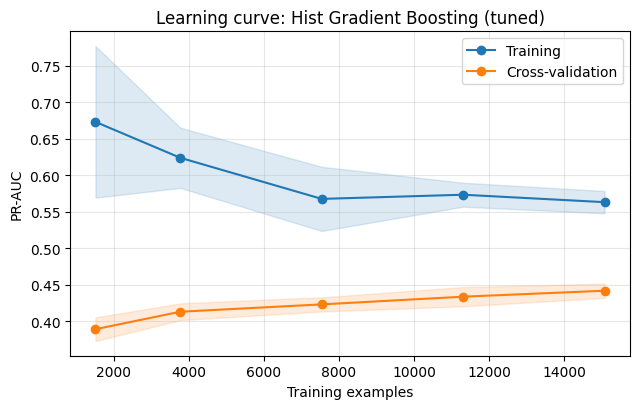

In [29]:
X_lc, y_lc = stratified_sample(X_train, y_train, LC_N)
sizes, tr, va = learning_curve(build(best_name).set_params(**best_params[best_name]), X_lc, y_lc,
                               train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], cv=cv,
                               scoring="average_precision", n_jobs=1, random_state=SEED)
plt.figure(figsize=(6.5, 4.2))
for arr, lab, col in [(tr, "Training", "tab:blue"), (va, "Cross-validation", "tab:orange")]:
    plt.plot(sizes, arr.mean(1), "o-", label=lab, color=col)
    plt.fill_between(sizes, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=0.15, color=col)
plt.xlabel("Training examples"); plt.ylabel("PR-AUC"); plt.title(f"Learning curve: {LABELS[best_name]}")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); show_fig("learning_curve")

**Your interpretation:** Do the two curves converge? Is there a gap, and does the validation curve still rise at the largest size? What does that suggest about collecting more data versus improving features?

### 2.12 Final evaluation on the held-out test set

Every model is applied to the test set with the threshold chosen on validation. Curves compare ranking quality (ROC and precision-recall), and the confusion matrix shows the selected model's errors at its threshold.

,ROC-AUC,PR-AUC,threshold,recall,precision,F1,F2,balanced acc,flagged %
model,,,,,,,,,
Logistic Regression (tuned),0.871,0.500,0.413,0.848,0.255,0.392,0.579,0.778,35.115
Random Forest (tuned),0.867,0.482,0.373,0.779,0.311,0.445,0.599,0.788,26.429
Hist Gradient Boosting (tuned),0.871,0.497,0.510,0.789,0.306,0.441,0.600,0.789,27.213
"SVM (RBF, subsample)",0.846,0.404,-0.498,0.846,0.252,0.389,0.575,0.775,35.403


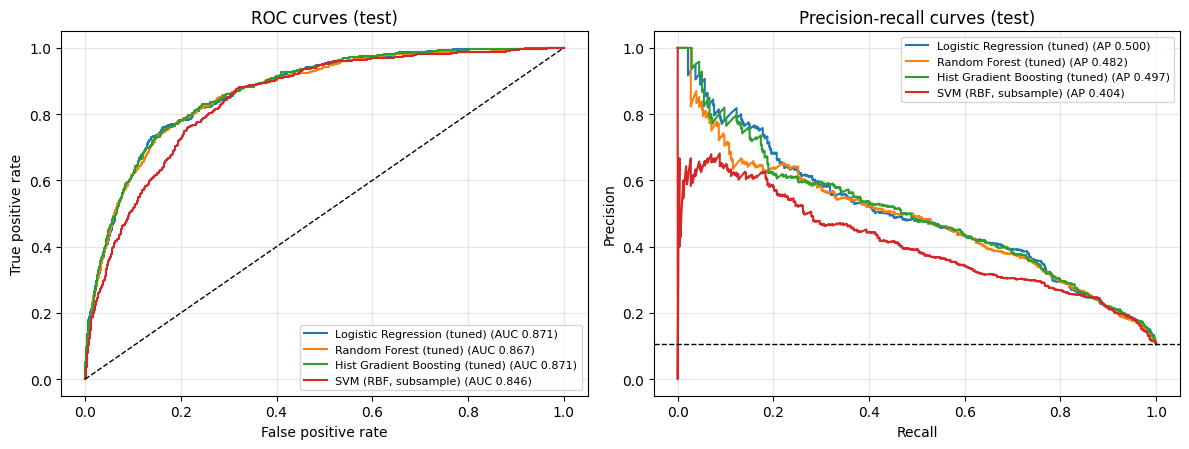

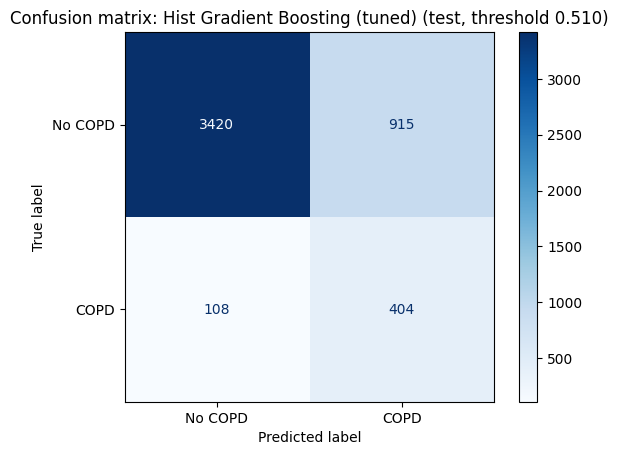

In [30]:
test_scores, test_rows = {}, []
for name, m in tuned.items():
    s = get_scores(m, X_test); test_scores[LABELS[name]] = s
    test_rows.append({"model": LABELS[name], **metrics(y_test, s, tuned_val[name]["thr"])})
svm = fitted["SVM (RBF, subsample)"]
s = get_scores(svm, X_test); test_scores["SVM (RBF, subsample)"] = s
test_rows.append({"model": "SVM (RBF, subsample)", **metrics(y_test, s, best_threshold(y_val, val_scores["SVM (RBF, subsample)"]))})
test_table = pd.DataFrame(test_rows).set_index("model")
display(test_table.round(3))
wb_table("test_results", test_table.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for lab, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s); ax[0].plot(fpr, tpr, label=f"{lab} (AUC {roc_auc_score(y_test, s):.3f})")
    p, r, _ = precision_recall_curve(y_test, s); ax[1].plot(r, p, label=f"{lab} (AP {average_precision_score(y_test, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test)")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (test)")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); show_fig("roc_pr_curves")

best_test_scores = test_scores[LABELS[best_name]]
pred = (best_test_scores >= best_thr).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No COPD", "COPD"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix: {LABELS[best_name]} (test, threshold {best_thr:.3f})"); show_fig("confusion_matrix")
wb_summary({"best_model": LABELS[best_name], "threshold": float(best_thr),
            **{f"test/{k}": float(v) for k, v in test_table.loc[LABELS[best_name]].items()}})

**Your interpretation:** Which model wins on the test set, and does it match the validation ranking? Read the confusion matrix: how many real COPD cases are missed, and how many people would be flagged unnecessarily? Is the model strong enough for a screening aid?

### 2.13 Threshold analysis

A screening tool is only useful if its trade-off can be stated in plain terms. For several target recall levels, the threshold is fixed on the validation set and then applied to the test set, showing what share of people would be flagged and how many of the flagged are real cases (precision).

,target recall (val),threshold,test recall,test precision,people flagged %
0,0.6,0.667,0.639,0.418,16.134
1,0.7,0.569,0.756,0.343,23.251
2,0.8,0.409,0.850,0.259,34.619
3,0.9,0.265,0.926,0.205,47.679


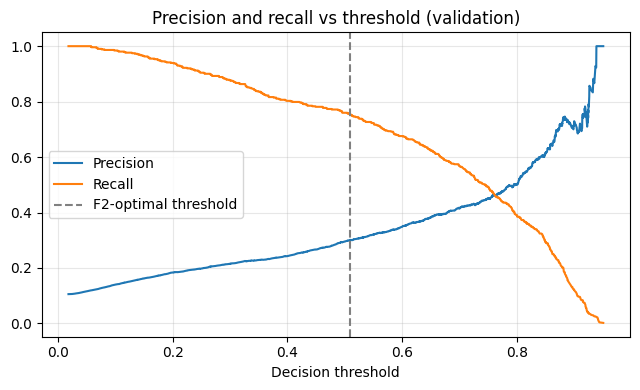

In [31]:
s_val = tuned_val[best_name]["scores"]
rows = []
for target in [0.60, 0.70, 0.80, 0.90]:
    prec, rec, thr = precision_recall_curve(y_val, s_val)
    ok = np.where(rec[:-1] >= target)[0]
    t = thr[ok[-1]]
    m = metrics(y_test, best_test_scores, t)
    rows.append({"target recall (val)": target, "threshold": t, "test recall": m["recall"],
                 "test precision": m["precision"], "people flagged %": m["flagged %"]})
thr_tbl = pd.DataFrame(rows).round(3)
display(thr_tbl)
wb_table("threshold_analysis", thr_tbl)

p, r, t = precision_recall_curve(y_val, s_val)
plt.figure(figsize=(6.5, 4)); plt.plot(t, p[:-1], label="Precision"); plt.plot(t, r[:-1], label="Recall")
plt.axvline(best_thr, color="gray", ls="--", label="F2-optimal threshold")
plt.xlabel("Decision threshold"); plt.title("Precision and recall vs threshold (validation)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); show_fig("precision_recall_vs_threshold")

### 2.14 Which features matter? Permutation importance and ablation

**Permutation importance** shuffles one feature at a time on validation data and measures how much PR-AUC drops. **Group ablation** retrains the model without a whole group of features. Together they test the feature list from Part 1 with evidence instead of assumption. Strongly correlated features can share importance, so read the ablation results alongside the importance plot.

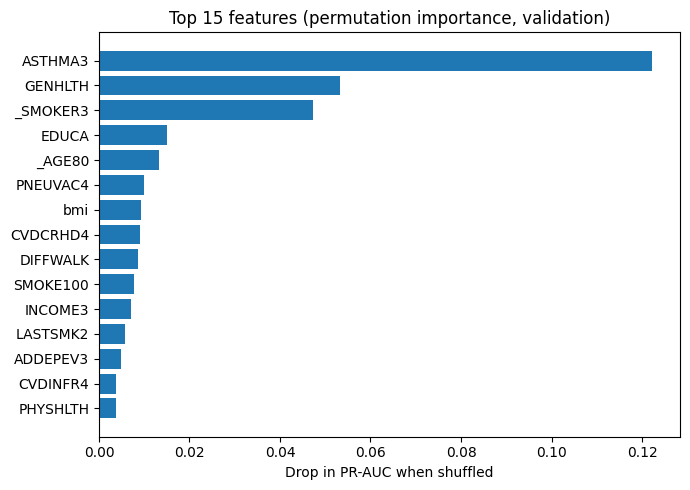

In [32]:
X_pi, y_pi = stratified_sample(X_val, y_val, PI_N)
pi = permutation_importance(best_model, X_pi, y_pi, scoring="average_precision", n_repeats=3,
                            random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=ALL_FEATURES).sort_values(ascending=False)
top = imp.head(15)[::-1]
plt.figure(figsize=(7, 5)); plt.barh(top.index, top.values, color="tab:blue")
plt.xlabel("Drop in PR-AUC when shuffled"); plt.title("Top 15 features (permutation importance, validation)")
plt.tight_layout(); show_fig("permutation_importance")
wb_table("permutation_importance", imp.head(20).rename("PR-AUC drop").to_frame())

In [33]:
GROUPS = {
    "Smoking & tobacco":  ["SMOKE100", "_SMOKER3", "SMOKDAY2", "LASTSMK2", "USENOW3"],
    "Alcohol":            ["alc_days_month", "alc_drinks_week"],
    "Health status":      ["GENHLTH", "PHYSHLTH", "MENTHLTH", "bmi", "EXERANY2", "DIFFWALK", "DIFFDRES", "DIFFALON"],
    "Comorbidities":      ["ASTHMA3", "CVDINFR4", "CVDCRHD4", "CVDSTRK3", "DIABETE4", "BPHIGH6", "TOLDHI3",
                           "ADDEPEV3", "HAVARTH4", "CHCKDNY2"],
    "Socio-demographics": ["MARITAL", "EMPLOY1", "EDUCA", "INCOME3", "VETERAN3", "_URBSTAT", "_STATE"],
    "Healthcare use":     ["CHECKUP1", "MEDCOST1", "FLUSHOT7", "PNEUVAC4"],
    "Physical/mental days (leakage check)": ["PHYSHLTH", "MENTHLTH"],
}
full_s = tuned_val[best_name]["scores"]
rows = [{"removed group": "none (all features)", "ROC-AUC": roc_auc_score(y_val, full_s),
         "PR-AUC": average_precision_score(y_val, full_s)}]
for g, cols in GROUPS.items():
    keep = [c for c in ALL_FEATURES if c not in cols]
    m = build(best_name, cols=keep).set_params(**best_params[best_name]).fit(X_train[keep], y_train)
    s = get_scores(m, X_val[keep])
    rows.append({"removed group": g, "ROC-AUC": roc_auc_score(y_val, s), "PR-AUC": average_precision_score(y_val, s)})
abl = pd.DataFrame(rows).set_index("removed group")
abl["PR-AUC change"] = abl["PR-AUC"] - abl.loc["none (all features)", "PR-AUC"]
wb_table("feature_group_ablation", abl.round(4))
abl.round(4)

,ROC-AUC,PR-AUC,PR-AUC change
removed group,,,
none (all features),0.8524,0.4723,0.0000
Smoking & tobacco,0.8301,0.4267,-0.0456
Alcohol,0.8522,0.4701,-0.0022
Health status,0.8414,0.4433,-0.0291
Comorbidities,0.8222,0.3784,-0.0939
Socio-demographics,0.8470,0.4609,-0.0114
Healthcare use,0.8502,0.4673,-0.0050
Physical/mental days (leakage check),0.8518,0.4682,-0.0041


**Your interpretation:** Which feature group costs the most performance when removed? Is smoking as dominant as expected? Does removing `PHYSHLTH` and `MENTHLTH` change the result much (these can partly reflect COPD symptoms, so a large drop is a leakage warning)? Which groups could be dropped with almost no loss?

### 2.15 Error analysis by subgroup

Recall and precision at the selected threshold are broken down by sex, age band, smoking status and income band on the **test set**. Large differences in recall between subgroups are a fairness and reliability concern worth discussing in the report. Groups with very few people give unstable estimates.

In [34]:
meta = df.loc[idx_test, META + ["is_female", "_SMOKER3", "INCOME3"]].copy()
meta["y"], meta["pred"] = y_test, pred

meta["Sex"] = np.where(meta["is_female"] == 1, "Female", "Male")
meta["Age band"] = meta["_AGEG5YR"].map({7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"})
meta["Smoking"] = meta["_SMOKER3"].map({1: "Current (daily)", 2: "Current (some days)", 3: "Former", 4: "Never"}).fillna("Unknown")
meta["Income"] = pd.cut(meta["INCOME3"], [0, 4, 7, 11], labels=["< $25k", "$25k-$75k", "> $75k"]).astype(object).fillna("Unknown")

def subgroup_table(col):
    g = meta.groupby(col)
    out = pd.DataFrame({"n": g.size(), "COPD rate": g["y"].mean(),
                        "recall": g.apply(lambda d: recall_score(d["y"], d["pred"]) if d["y"].sum() else np.nan),
                        "precision": g.apply(lambda d: precision_score(d["y"], d["pred"], zero_division=0)),
                        "flagged %": g["pred"].mean() * 100})
    out.index = [f"{col}: {i}" for i in out.index]
    return out

subgroups = pd.concat([subgroup_table(c) for c in ["Sex", "Age band", "Smoking", "Income"]]).round(3)
wb_table("subgroup_error_analysis", subgroups)
subgroups

,n,COPD rate,recall,precision,flagged %
Sex: Female,2653,0.112,0.819,0.314,29.250
Sex: Male,2194,0.098,0.748,0.295,24.749
Age band: 50-54,612,0.051,0.645,0.274,11.928
Age band: 55-59,613,0.080,0.837,0.350,19.086
Age band: 60-64,737,0.100,0.797,0.347,23.066
Age band: 65-69,799,0.114,0.813,0.322,28.786
Age band: 70-74,764,0.116,0.775,0.290,31.152
Age band: 75-79,611,0.160,0.776,0.344,36.170
Age band: 80+,711,0.113,0.812,0.241,37.975
Smoking: Current (daily),330,0.330,0.954,0.418,75.455


In [35]:
fn = meta[(meta.y == 1) & (meta.pred == 0)]
tp = meta[(meta.y == 1) & (meta.pred == 1)]
share = lambda d: d["Smoking"].value_counts(normalize=True).round(3)
pd.DataFrame({"missed cases (false negatives)": share(fn), "caught cases (true positives)": share(tp)}).fillna(0)

,missed cases (false negatives),caught cases (true positives)
Smoking,,
Current (daily),0.046,0.257
Current (some days),0.037,0.074
Former,0.407,0.510
Never,0.426,0.124
Unknown,0.083,0.035


**Your interpretation:** Which subgroups does the model miss most often? Are the missed cases mostly people who never smoked (the hardest cases for any model that relies on smoking history)? What does this imply for who a screening programme built on this model might overlook?

### 2.16 Save the best model, threshold and split

The pipeline (preprocessing + model), the decision threshold and the split indices are saved to the Drive folder. The split indices point to rows of the Part 1 Parquet file, so the deep learning part (Part 3) can load exactly the same train/validation/test rows.

In [36]:
joblib.dump(best_model, f"{MODEL_DIR}/best_traditional_model{SUFFIX}.joblib")
np.savez(f"{MODEL_DIR}/split_indices{SUFFIX}.npz", train=idx_train, val=idx_val, test=idx_test)
with open(f"{MODEL_DIR}/best_traditional_meta{SUFFIX}.json", "w") as f:
    json.dump({"model": LABELS[best_name], "threshold": float(best_thr), "params": {k: str(v) for k, v in best_params[best_name].items()},
               "test_metrics": {k: float(v) for k, v in test_table.loc[LABELS[best_name]].items()},
               "features": ALL_FEATURES, "seed": SEED}, f, indent=2)
test_table.round(4).to_csv(f"{MODEL_DIR}/traditional_test_results{SUFFIX}.csv")
print(os.listdir(MODEL_DIR))

if RUN is not None:
    art = wandb.Artifact("best-traditional-model", type="model",
                         metadata={"model": LABELS[best_name], "threshold": float(best_thr)})
    model_file = f"{MODEL_DIR}/best_traditional_model{SUFFIX}.joblib"
    if os.path.getsize(model_file) < 500e6:          # skip very large models (e.g. a huge Random Forest)
        art.add_file(model_file)
    art.add_file(f"{MODEL_DIR}/best_traditional_meta{SUFFIX}.json")
    art.add_file(f"{MODEL_DIR}/split_indices{SUFFIX}.npz")
    RUN.log_artifact(art)
wb_end()

['best_traditional_model_quick.joblib', 'split_indices_quick.npz', 'best_traditional_meta_quick.json', 'traditional_test_results_quick.csv']


wandb: WARNING Artifact "best-traditional-model" already exists with the same content. No new version will be created.


best_model,Hist Gradient Boosti...
test/F1,0.44129
test/F2,0.59994
test/PR-AUC,0.49723
test/ROC-AUC,0.87148
test/balanced acc,0.78899
test/flagged %,27.21271
test/precision,0.30629
test/recall,0.78906
test/threshold,0.50977
+1,...


### 2.17 Summary for the report

*Fill in after the full run:* the best traditional model and its tuned settings; its test ROC-AUC, PR-AUC, recall and precision at the chosen threshold; the most important feature groups; the main error patterns; and the limitations (self-reported diagnoses, undiagnosed cases labelled negative, cross-sectional data). These numbers are the benchmark the deep learning models in Part 3 will be compared against.

## Part 3. Deep learning (TensorFlow/Keras)

This part trains neural networks on **exactly the same train / validation / test rows** as Part 2, so the comparison with the traditional models is fair. It uses the Keras **Functional API** and a **`tf.data`** input pipeline.

### 3.1 Setup and checks

In [37]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import OrdinalEncoder

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

DL_EPOCHS   = 100 if not QUICK_RUN else 3     # upper limit; early stopping normally ends training sooner
DL_PATIENCE = 8
DL_BATCH    = 1024
BOOTSTRAPS  = 200 if not QUICK_RUN else 40

needed = ["df", "y", "idx_train", "idx_val", "idx_test", "X_train", "X_val", "X_test", "y_train", "y_val", "y_test",
          "ALL_FEATURES", "CONT", "BINARY", "ORDINAL", "NOMINAL", "make_preprocessor", "metrics", "best_threshold",
          "get_scores", "Winsorizer", "wb_start", "wb_end", "wb_log", "wb_table"]
absent = [n for n in needed if n not in globals()]
assert not absent, f"Run Part 0 and sections 2.1-2.5 first. Missing: {absent}"

# the split must be identical to the one saved by Part 2
split_file = f"{MODEL_DIR}/split_indices{SUFFIX}.npz"
if os.path.exists(split_file):
    saved = np.load(split_file)
    assert all((saved[k] == v).all() for k, v in zip(["train", "val", "test"], [idx_train, idx_val, idx_test])), "split differs from Part 2"
    print("Split matches the one saved by Part 2.")

TensorFlow 2.21.0 | GPUs: []
Split matches the one saved by Part 2.


### 3.2 Data preparation

The preprocessing is the one used in Part 2 (clip outliers, impute with missing-indicators, scale numeric features, one-hot encode categoricals) and is **fitted on the training rows only**. The result is a dense `float32` matrix per split. Class weights are computed from the training labels so that the rare COPD class counts as much as the common one during training.

In [38]:
prep = make_preprocessor(ALL_FEATURES, "indicator", scale=True)
Xtr = prep.fit_transform(X_train).astype("float32")
Xva = prep.transform(X_val).astype("float32")
Xte = prep.transform(X_test).astype("float32")
print("feature matrices:", Xtr.shape, Xva.shape, Xte.shape)

n0, n1 = int((y_train == 0).sum()), int((y_train == 1).sum())
CLASS_WEIGHT = {0: 0.5 * len(y_train) / n0, 1: 0.5 * len(y_train) / n1}
print("class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

feature matrices: (22617, 145) (4846, 145) (4847, 145)
class weights: {0: 0.559, 1: 4.736}


### 3.3 `tf.data` input pipelines

Each split becomes a `tf.data.Dataset`. The training pipeline reshuffles every epoch, all pipelines are batched, and `prefetch` prepares the next batch while the current one is being processed. The validation and test pipelines are **not** shuffled, so predictions stay aligned with the labels.

In [39]:
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(features, labels, batch, training):
    ds = tf.data.Dataset.from_tensor_slices((features, np.asarray(labels, dtype="float32")))
    if training:
        ds = ds.shuffle(buffer_size=min(len(labels), 100_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(AUTOTUNE)

ds_example = make_ds(Xtr, y_train, DL_BATCH, True)
for xb, yb in ds_example.take(1):
    print("one training batch:", xb.shape, yb.shape)

one training batch: (1024, 145) (1024,)


### 3.4 Model definitions (Functional API)

**MLP.** Stacked dense layers; each block is Dense → (batch normalisation) → activation → dropout, followed by a single sigmoid unit that outputs the probability of a COPD report. Width, depth, dropout, L2 strength, batch normalisation, activation and learning rate are all arguments, so the experiments below only change the configuration.

**Embedding model.** A multi-input network: numeric features go in as one vector, while each categorical variable (marital status, employment, diabetes status, smoker status, state, and so on) has its own input and a learned embedding. Embeddings can represent similarities between categories, which one-hot encoding cannot. Missing values are kept as their own category, as in Part 2.

Every model is compiled with binary cross-entropy and tracks ROC-AUC, PR-AUC, precision and recall per epoch.

In [40]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="roc_auc"), keras.metrics.AUC(name="pr_auc", curve="PR"),
                           keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])

def dense_stack(x, units, dropout, l2, batchnorm, activation):
    reg = keras.regularizers.l2(l2) if l2 else None
    for i, u in enumerate(units):
        x = layers.Dense(u, activation=None if batchnorm else activation, kernel_regularizer=reg, name=f"dense_{i}")(x)
        if batchnorm:
            x = layers.BatchNormalization(name=f"bn_{i}")(x)
            x = layers.Activation(activation, name=f"act_{i}")(x)
        if dropout:
            x = layers.Dropout(dropout, name=f"drop_{i}")(x)
    return x

def build_mlp(input_dim, units=(128, 64), dropout=0.3, l2=1e-4, batchnorm=True, activation="relu", lr=1e-3):
    inp = keras.Input(shape=(input_dim,), name="features")
    x = dense_stack(inp, units, dropout, l2, batchnorm, activation)
    out = layers.Dense(1, activation="sigmoid", name="copd_probability")(x)
    model = keras.Model(inp, out, name="mlp")
    compile_model(model, lr)
    return model

# ---- embedding model: data preparation -------------------------------------
NUM_COLS = CONT + BINARY + ORDINAL
CAT_KEYS = ["cat_" + c.strip("_") for c in NOMINAL]

num_prep = make_preprocessor(NUM_COLS, "indicator", scale=True)
Xn_tr = num_prep.fit_transform(X_train[NUM_COLS]).astype("float32")
Xn_va = num_prep.transform(X_val[NUM_COLS]).astype("float32")
Xn_te = num_prep.transform(X_test[NUM_COLS]).astype("float32")

cat_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
fill = lambda d: d[NOMINAL].fillna(-1)               # missing / "not asked" becomes its own category
C_tr = cat_enc.fit_transform(fill(X_train)).astype("int32") + 1   # +1 so that unseen categories map to 0
C_va = cat_enc.transform(fill(X_val)).astype("int32") + 1
C_te = cat_enc.transform(fill(X_test)).astype("int32") + 1
CARDS = [len(c) + 1 for c in cat_enc.categories_]

def emb_features(Xn, C):
    return {"numeric": Xn, **{k: C[:, i:i + 1] for i, k in enumerate(CAT_KEYS)}}

def build_embedding_model(num_dim, cards, units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3, batchnorm=True, activation="relu"):
    num_in = keras.Input(shape=(num_dim,), name="numeric")
    cat_ins, embs = [], []
    for key, card in zip(CAT_KEYS, cards):
        i = keras.Input(shape=(1,), dtype="int32", name=key)
        e = layers.Embedding(card, min(8, card // 2 + 1), name="emb_" + key[4:])(i)
        cat_ins.append(i); embs.append(layers.Flatten()(e))
    x = layers.Concatenate()([num_in] + embs)
    x = dense_stack(x, units, dropout, l2, batchnorm, activation)
    out = layers.Dense(1, activation="sigmoid", name="copd_probability")(x)
    model = keras.Model([num_in] + cat_ins, out, name="embedding_mlp")
    compile_model(model, lr)
    return model

build_mlp(Xtr.shape[1]).summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 145)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_0 (Dense)                 │ (None, 128)            │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_0 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_0 (Activation)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_0 (Dropout)                │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_1 (Activation)              │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ copd_probability (Dense)        │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,777 (108.50 KB)

 Trainable params: 27,393 (107.00 KB)

 Non-trainable params: 384 (1.50 KB)

### 3.5 Training helper

One function trains a configuration and records everything in the same way: it builds the model, trains it on the `tf.data` pipeline with class weights, early stopping and learning-rate reduction, logs every epoch to Weights & Biases, scores the validation set, picks the F2-optimal threshold on the validation set and stores the metrics. All experiments call it, so they are compared on identical terms. Random seeds are fixed before each run.

In [41]:
class WBLogger(keras.callbacks.Callback):
    # sends the metrics of every epoch to the active Weights & Biases run
    def on_epoch_end(self, epoch, logs=None):
        row = {"epoch": epoch + 1, **{k: float(v) for k, v in (logs or {}).items()}}
        try:
            row["lr"] = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))
        except Exception:
            pass
        wb_log(row)

DL_RESULTS, DL_STORE = [], {}

def train_dnn(name, group, cfg=None, embed=False):
    cfg = {"units": (128, 64), "dropout": 0.3, "l2": 1e-4, "batchnorm": True, "activation": "relu",
           "lr": 1e-3, "batch": DL_BATCH, **(cfg or {})}
    wb_start(name, group, {**{k: str(v) for k, v in cfg.items()}, "embeddings": embed, "max_epochs": DL_EPOCHS})
    keras.utils.set_random_seed(SEED)
    arch = {k: cfg[k] for k in ("units", "dropout", "l2", "batchnorm", "activation", "lr")}
    if embed:
        model = build_embedding_model(Xn_tr.shape[1], CARDS, **arch)
        f_tr, f_va = emb_features(Xn_tr, C_tr), emb_features(Xn_va, C_va)
    else:
        model = build_mlp(Xtr.shape[1], **arch)
        f_tr, f_va = Xtr, Xva
    ds_tr, ds_va = make_ds(f_tr, y_train, cfg["batch"], True), make_ds(f_va, y_val, 4096, False)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=DL_PATIENCE, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=3, min_lr=1e-6),
                 WBLogger()]
    t0 = time.time()
    hist = model.fit(ds_tr, validation_data=ds_va, epochs=DL_EPOCHS, class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=0)
    s = model.predict(ds_va, verbose=0).ravel()
    thr = best_threshold(y_val, s)
    res = {"experiment": name, "group": group, **metrics(y_val, s, thr),
           "epochs run": len(hist.history["loss"]), "best epoch": int(np.argmax(hist.history["val_pr_auc"])) + 1,
           "parameters": model.count_params(), "fit time (s)": time.time() - t0}
    wb_log({f"val/{k}": v for k, v in res.items() if k not in ("experiment", "group")}); wb_end()
    DL_RESULTS.append(res)
    DL_STORE[name] = {"model": model, "history": hist.history, "val_scores": s, "thr": thr, "embed": embed, "cfg": cfg}
    print(f"{name:34s} PR-AUC {res['PR-AUC']:.3f}  ROC-AUC {res['ROC-AUC']:.3f}  epochs {res['epochs run']:3d} (best {res['best epoch']})  {res['fit time (s)']:.0f}s")
    return res

def group_table(group):
    d = pd.DataFrame([r for r in DL_RESULTS if r["group"] == group]).set_index("experiment")
    return d[["PR-AUC", "ROC-AUC", "recall", "precision", "F2", "epochs run", "best epoch", "parameters", "fit time (s)"]].round(3)

### 3.6 Experiment A: architecture (depth and width)

Four MLPs of increasing capacity are trained with the same regularisation and optimiser settings, to find out how much model capacity this problem needs. Tabular health survey data often saturates early, so a larger network is not guaranteed to be better.

In [42]:
ARCH = {"shallow (64)": (64,), "medium (128-64)": (128, 64), "deep (256-128-64)": (256, 128, 64), "wide (512-256)": (512, 256)}
for label, units in ARCH.items():
    train_dnn(f"arch | {label}", "dl-exp-architecture", {"units": units})
group_table("dl-exp-architecture")

epoch,▁▅█
learning_rate,▁▁▁
loss,█▂▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▆█
recall,▁█▇
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


arch | shallow (64)                PR-AUC 0.441  ROC-AUC 0.844  epochs   3 (best 3)  4s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▂▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▅█
recall,▁█▇
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


arch | medium (128-64)             PR-AUC 0.440  ROC-AUC 0.846  epochs   3 (best 3)  6s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▃▁
lr,▁▁▁
pr_auc,▁▅█
precision,▁▆█
recall,█▁▂
roc_auc,▁▆█
val/F1,▁
val/F2,▁
+16,...


arch | deep (256-128-64)           PR-AUC 0.443  ROC-AUC 0.845  epochs   3 (best 3)  8s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▃▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▇█
recall,▁▅█
roc_auc,▁▆█
val/F1,▁
val/F2,▁
+16,...


arch | wide (512-256)              PR-AUC 0.449  ROC-AUC 0.851  epochs   3 (best 3)  7s


,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters,fit time (s)
experiment,,,,,,,,,
arch | shallow (64),0.441,0.844,0.699,0.306,0.556,3,3,9665,3.774
arch | medium (128-64),0.440,0.846,0.771,0.283,0.573,3,3,27777,5.971
arch | deep (256-128-64),0.443,0.845,0.730,0.309,0.574,3,3,80385,7.501
arch | wide (512-256),0.449,0.851,0.797,0.269,0.573,3,3,209409,6.908


**Your interpretation:** Does a bigger network help? Compare the PR-AUC of the shallow and the deep models and look at the parameter counts and training times. At which point do the extra layers stop paying off?

### 3.7 Experiment B: regularisation

The medium network (128-64) from Experiment A is the reference. Variants remove regularisation entirely, use stronger dropout, use stronger L2 weight decay, or remove batch normalisation. Regularisation fights overfitting, which should show up as a smaller gap between training and validation curves.

In [43]:
REG = {"no regularisation": dict(dropout=0.0, l2=0.0), "dropout 0.5": dict(dropout=0.5),
       "L2 1e-3": dict(l2=1e-3), "no batch norm": dict(batchnorm=False)}
for label, cfg in REG.items():
    train_dnn(f"reg | {label}", "dl-exp-regularisation", {"units": (128, 64), **cfg})
pd.concat([group_table("dl-exp-architecture").loc[["arch | medium (128-64)"]].rename(index={"arch | medium (128-64)": "reference (dropout 0.3, L2 1e-4, BN)"}),
           group_table("dl-exp-regularisation")])

epoch,▁▅█
learning_rate,▁▁▁
loss,█▃▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▆█
recall,▁██
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


reg | no regularisation            PR-AUC 0.440  ROC-AUC 0.852  epochs   3 (best 3)  6s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▂▁
lr,▁▁▁
pr_auc,▁▇█
precision,▁▅█
recall,▁██
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


reg | dropout 0.5                  PR-AUC 0.411  ROC-AUC 0.840  epochs   3 (best 3)  5s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▃▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▅█
recall,▁█▇
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


reg | L2 1e-3                      PR-AUC 0.439  ROC-AUC 0.847  epochs   3 (best 3)  7s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▂▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▇█
recall,▁▇█
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


reg | no batch norm                PR-AUC 0.447  ROC-AUC 0.849  epochs   3 (best 3)  4s


,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters,fit time (s)
experiment,,,,,,,,,
"reference (dropout 0.3, L2 1e-4, BN)",0.440,0.846,0.771,0.283,0.573,3,3,27777,5.971
reg | no regularisation,0.440,0.852,0.803,0.273,0.579,3,3,27777,5.556
reg | dropout 0.5,0.411,0.840,0.762,0.278,0.565,3,3,27777,5.068
reg | L2 1e-3,0.439,0.847,0.754,0.290,0.571,3,3,27777,6.517
reg | no batch norm,0.447,0.849,0.754,0.299,0.578,3,3,27009,3.511


**Your interpretation:** Which regularisation setting generalises best? Is the unregularised network noticeably worse, and does removing batch normalisation change training speed or stability

### 3.8 Experiment C: optimisation (learning rate and batch size)

Learning rate and batch size control how fast and how stably the network learns. A rate that is too high makes training unstable, while one that is too low is slow and may stop early on a plateau. The default is a learning rate of 1e-3 and a batch size of 1,024.

In [44]:
OPT = {"lr 1e-2": dict(lr=1e-2), "lr 1e-4": dict(lr=1e-4), "batch 512": dict(batch=512), "batch 4096": dict(batch=4096)}
for label, cfg in OPT.items():
    train_dnn(f"opt | {label}", "dl-exp-optimisation", {"units": (128, 64), **cfg})
pd.concat([group_table("dl-exp-architecture").loc[["arch | medium (128-64)"]].rename(index={"arch | medium (128-64)": "reference (lr 1e-3, batch 1024)"}),
           group_table("dl-exp-optimisation")])

epoch,▁▅█
learning_rate,▁▁▁
loss,█▂▁
lr,▁▁▁
pr_auc,▁▇█
precision,▁▆█
recall,▁██
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


opt | lr 1e-2                      PR-AUC 0.474  ROC-AUC 0.853  epochs   3 (best 3)  5s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▄▁
lr,▁▁▁
pr_auc,▁▄█
precision,▁▅█
recall,▁▅█
roc_auc,▁▅█
val/F1,▁
val/F2,▁
+16,...


opt | lr 1e-4                      PR-AUC 0.264  ROC-AUC 0.765  epochs   3 (best 3)  5s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▂▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▇█
recall,▁▇█
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


opt | batch 512                    PR-AUC 0.454  ROC-AUC 0.851  epochs   3 (best 3)  5s


epoch,▁▅█
learning_rate,▁▁▁
loss,█▂▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▇█
recall,▁▆█
roc_auc,▁▆█
val/F1,▁
val/F2,▁
+16,...


opt | batch 4096                   PR-AUC 0.358  ROC-AUC 0.820  epochs   3 (best 3)  12s


,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters,fit time (s)
experiment,,,,,,,,,
"reference (lr 1e-3, batch 1024)",0.440,0.846,0.771,0.283,0.573,3,3,27777,5.971
opt | lr 1e-2,0.474,0.853,0.758,0.295,0.577,3,3,27777,4.926
opt | lr 1e-4,0.264,0.765,0.758,0.203,0.490,3,3,27777,4.944
opt | batch 512,0.454,0.851,0.721,0.323,0.578,3,3,27777,4.749
opt | batch 4096,0.358,0.820,0.791,0.240,0.542,3,3,27777,11.654


**Your interpretation:** Which learning rate and batch size work best? Did the high learning rate stop early or fluctuate, and did the small rate need many more epochs?

### 3.9 Experiment D: embeddings for categorical variables

The embedding model (multi-input Functional API) replaces one-hot encoding of the ten categorical variables with learned embeddings, while keeping the same hidden layers as the reference MLP. If embeddings help, the categories (for example states or employment types) carry structure that one-hot encoding cannot express.

In [45]:
train_dnn("embeddings | medium (128-64)", "dl-exp-embeddings", {"units": (128, 64)}, embed=True)
pd.concat([group_table("dl-exp-architecture").loc[["arch | medium (128-64)"]].rename(index={"arch | medium (128-64)": "one-hot MLP (reference)"}),
           group_table("dl-exp-embeddings")])

epoch,▁▅█
learning_rate,▁▁▁
loss,█▃▁
lr,▁▁▁
pr_auc,▁▆█
precision,▁▇█
recall,▁██
roc_auc,▁▇█
val/F1,▁
val/F2,▁
+16,...


embeddings | medium (128-64)       PR-AUC 0.435  ROC-AUC 0.843  epochs   3 (best 3)  8s


,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters,fit time (s)
experiment,,,,,,,,,
one-hot MLP (reference),0.440,0.846,0.771,0.283,0.573,3,3,27777,5.971
embeddings | medium (128-64),0.435,0.843,0.744,0.292,0.568,3,3,22715,8.306


**Your interpretation:** Do embeddings beat one-hot encoding? Is the difference larger than the run-to-run variation you would expect, or small enough to be noise?

### 3.10 Model selection and learning curves

All deep learning runs are compared on the validation set. The configuration with the highest validation PR-AUC is selected. Its **learning curves** (loss and PR-AUC per epoch, training against validation) show whether it overfits (validation gets worse while training keeps improving), underfits (both curves stay poor) or trains well (both converge together).

,group,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters
experiment,,,,,,,,,
opt | lr 1e-2,dl-exp-optimisation,0.474,0.853,0.758,0.295,0.577,3,3,27777
opt | batch 512,dl-exp-optimisation,0.454,0.851,0.721,0.323,0.578,3,3,27777
arch | wide (512-256),dl-exp-architecture,0.449,0.851,0.797,0.269,0.573,3,3,209409
reg | no batch norm,dl-exp-regularisation,0.447,0.849,0.754,0.299,0.578,3,3,27009
arch | deep (256-128-64),dl-exp-architecture,0.443,0.845,0.730,0.309,0.574,3,3,80385
arch | shallow (64),dl-exp-architecture,0.441,0.844,0.699,0.306,0.556,3,3,9665
reg | no regularisation,dl-exp-regularisation,0.440,0.852,0.803,0.273,0.579,3,3,27777
arch | medium (128-64),dl-exp-architecture,0.440,0.846,0.771,0.283,0.573,3,3,27777
reg | L2 1e-3,dl-exp-regularisation,0.439,0.847,0.754,0.290,0.571,3,3,27777



Selected deep learning model: opt | lr 1e-2 | validation threshold: 0.574


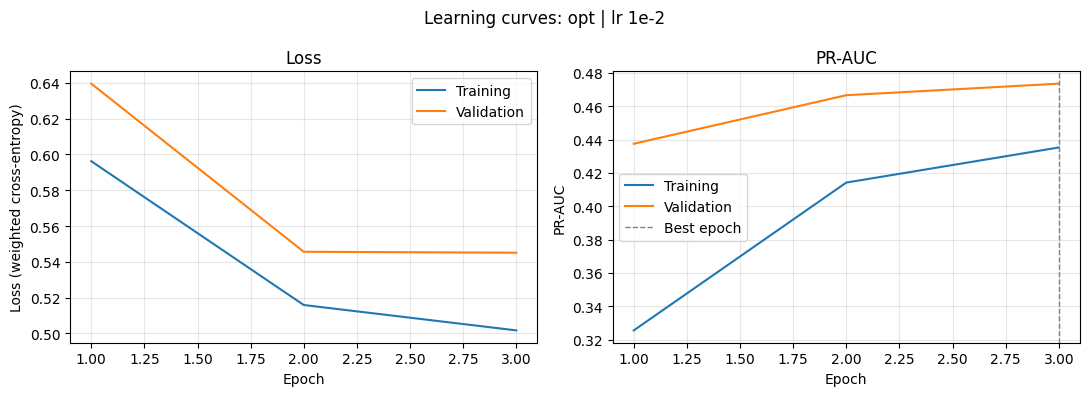

In [46]:
dl_df = pd.DataFrame(DL_RESULTS).set_index("experiment").sort_values("PR-AUC", ascending=False)
display(dl_df[["group", "PR-AUC", "ROC-AUC", "recall", "precision", "F2", "epochs run", "best epoch", "parameters"]].round(3))

best_dl = dl_df.index[0]
store = DL_STORE[best_dl]
print("\nSelected deep learning model:", best_dl, "| validation threshold:", round(float(store["thr"]), 3))

wb_start("final-dl", "dl-final", {"model": best_dl, **{k: str(v) for k, v in store["cfg"].items()}, "embeddings": store["embed"]}, job_type="evaluate")
wb_table("dl_experiments", dl_df[["group", "PR-AUC", "ROC-AUC", "recall", "precision", "F2", "epochs run", "best epoch", "parameters"]].round(4))

h = store["history"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ep = np.arange(1, len(h["loss"]) + 1)
ax[0].plot(ep, h["loss"], label="Training"); ax[0].plot(ep, h["val_loss"], label="Validation")
ax[0].set(xlabel="Epoch", ylabel="Loss (weighted cross-entropy)", title="Loss")
ax[1].plot(ep, h["pr_auc"], label="Training"); ax[1].plot(ep, h["val_pr_auc"], label="Validation")
ax[1].axvline(int(np.argmax(h["val_pr_auc"])) + 1, color="gray", ls="--", lw=1, label="Best epoch")
ax[1].set(xlabel="Epoch", ylabel="PR-AUC", title="PR-AUC")
for a in ax: a.legend(); a.grid(alpha=0.3)
fig.suptitle(f"Learning curves: {best_dl}"); plt.tight_layout(); show_fig("dl_learning_curves")

**Your interpretation:** Where does validation PR-AUC peak, and what happens after that? Is there a gap between training and validation, and what does early stopping do? Did the learning-rate reduction help?

### 3.11 Test-set evaluation and comparison with the best traditional model

The selected network is evaluated **once** on the test set, with the threshold chosen on the validation set. It is compared with the best traditional model from Part 2 using the same metrics and the same test rows. The curves show ranking quality, the confusion matrix shows the errors of the network, and **bootstrap confidence intervals** (resampling the test set) show whether the difference between the two models is larger than chance.

,ROC-AUC,PR-AUC,threshold,recall,precision,F1,F2,balanced acc,flagged %
Best traditional: Hist Gradient Boosting (tuned),0.871,0.497,0.510,0.789,0.306,0.441,0.600,0.789,27.213
Best deep learning: opt | lr 1e-2,0.870,0.499,0.574,0.785,0.301,0.436,0.594,0.785,27.522


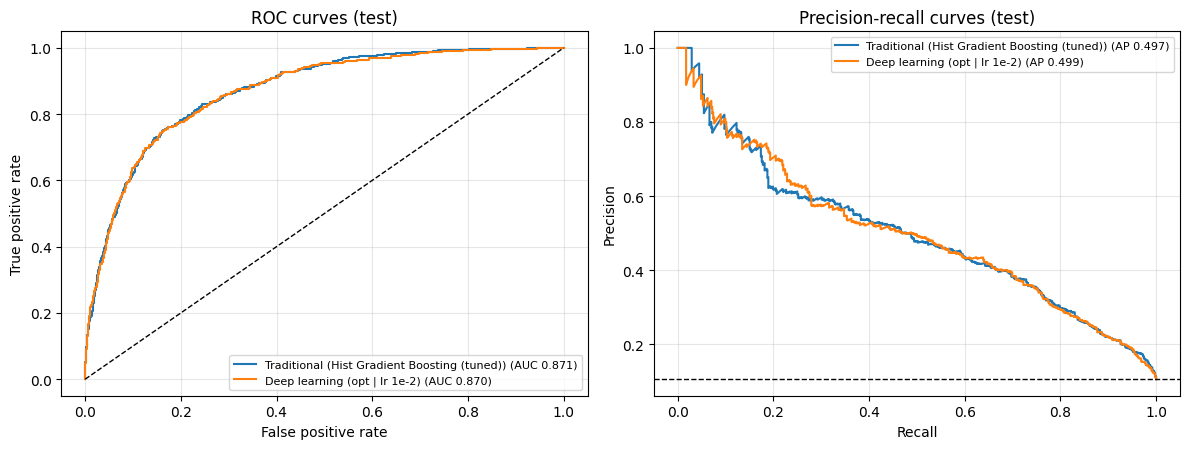

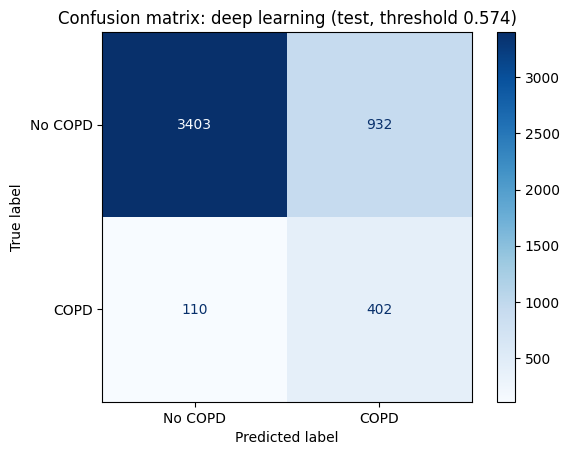

In [47]:
f_te = emb_features(Xn_te, C_te) if store["embed"] else Xte
dl_scores = store["model"].predict(make_ds(f_te, y_test, 4096, False), verbose=0).ravel()
dl_thr = float(store["thr"])

# best traditional model from Part 2 (from memory, or reloaded from disk after a restart)
if "best_test_scores" in globals():
    trad_scores, trad_thr, trad_label = best_test_scores, float(best_thr), LABELS[best_name]
else:
    trad_model = joblib.load(f"{MODEL_DIR}/best_traditional_model{SUFFIX}.joblib")
    with open(f"{MODEL_DIR}/best_traditional_meta{SUFFIX}.json") as f_:
        trad_meta = json.load(f_)
    trad_scores, trad_thr, trad_label = get_scores(trad_model, X_test), float(trad_meta["threshold"]), trad_meta["model"]

cmp = pd.DataFrame({f"Best traditional: {trad_label}": metrics(y_test, trad_scores, trad_thr),
                    f"Best deep learning: {best_dl}": metrics(y_test, dl_scores, dl_thr)}).T
display(cmp.round(3))
wb_table("traditional_vs_deep_learning_test", cmp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for lab, s in [(f"Traditional ({trad_label})", trad_scores), (f"Deep learning ({best_dl})", dl_scores)]:
    fpr, tpr, _ = roc_curve(y_test, s); ax[0].plot(fpr, tpr, label=f"{lab} (AUC {roc_auc_score(y_test, s):.3f})")
    p, r, _ = precision_recall_curve(y_test, s); ax[1].plot(r, p, label=f"{lab} (AP {average_precision_score(y_test, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test)")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (test)")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); show_fig("dl_vs_traditional_curves")

pred_dl = (dl_scores >= dl_thr).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_dl), display_labels=["No COPD", "COPD"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix: deep learning (test, threshold {dl_thr:.3f})"); show_fig("dl_confusion_matrix")

In [48]:
# bootstrap confidence intervals for the difference (deep learning minus traditional) on the test set
rng = np.random.default_rng(SEED)
d_pr, d_roc = [], []
for _ in range(BOOTSTRAPS):
    ii = rng.integers(0, len(y_test), len(y_test))
    if y_test[ii].sum() == 0:
        continue
    d_pr.append(average_precision_score(y_test[ii], dl_scores[ii]) - average_precision_score(y_test[ii], trad_scores[ii]))
    d_roc.append(roc_auc_score(y_test[ii], dl_scores[ii]) - roc_auc_score(y_test[ii], trad_scores[ii]))
ci = lambda d: (np.mean(d), *np.percentile(d, [2.5, 97.5]))
boot = pd.DataFrame({"PR-AUC difference": ci(d_pr), "ROC-AUC difference": ci(d_roc)}, index=["mean", "2.5%", "97.5%"]).T.round(4)
display(boot)
print("If the interval contains 0, the two models are not clearly different on this test set.")
wb_table("bootstrap_difference", boot)

,mean,2.5%,97.5%
PR-AUC difference,0.0029,-0.0109,0.0160
ROC-AUC difference,-0.0020,-0.0072,0.0039


If the interval contains 0, the two models are not clearly different on this test set.


**Your interpretation:** Which family wins on the test set, and by how much? Does the bootstrap interval for the difference include zero? If the two are close, say so honestly: on tabular survey data, gradient boosting often matches or beats neural networks, and the main finding may be that the extra complexity of deep learning is not justified here.

### 3.12 Threshold analysis and subgroup recall for the deep learning model

The threshold analysis states the screening trade-off in plain terms (as in Part 2). The subgroup table compares **recall** for the two models across sex, age band, smoking status and income, to see whether either model fails for particular groups.

In [49]:
s_val_dl = store["val_scores"]
rows = []
for target in [0.60, 0.70, 0.80, 0.90]:
    prec, rec, thr = precision_recall_curve(y_val, s_val_dl)
    ok = np.where(rec[:-1] >= target)[0]
    m = metrics(y_test, dl_scores, thr[ok[-1]])
    rows.append({"target recall (val)": target, "threshold": thr[ok[-1]], "test recall": m["recall"],
                 "test precision": m["precision"], "people flagged %": m["flagged %"]})
dl_thr_tbl = pd.DataFrame(rows).round(3)
display(dl_thr_tbl)
wb_table("dl_threshold_analysis", dl_thr_tbl)

,target recall (val),threshold,test recall,test precision,people flagged %
0,0.6,0.727,0.652,0.415,16.588
1,0.7,0.623,0.760,0.339,23.643
2,0.8,0.499,0.844,0.265,33.629
3,0.9,0.334,0.926,0.208,47.019


In [50]:
m3 = df.loc[idx_test, ["_AGEG5YR", "is_female", "_SMOKER3", "INCOME3"]].copy()
m3["y"] = y_test
m3["pred_trad"] = (trad_scores >= trad_thr).astype(int)
m3["pred_dl"] = (dl_scores >= dl_thr).astype(int)
m3["Sex"] = np.where(m3["is_female"] == 1, "Female", "Male")
m3["Age band"] = m3["_AGEG5YR"].map({7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"})
m3["Smoking"] = m3["_SMOKER3"].map({1: "Current (daily)", 2: "Current (some days)", 3: "Former", 4: "Never"}).fillna("Unknown")
m3["Income"] = pd.cut(m3["INCOME3"], [0, 4, 7, 11], labels=["< $25k", "$25k-$75k", "> $75k"]).astype(object).fillna("Unknown")

def recall_by(col):
    g = m3[m3["y"] == 1].groupby(col)
    out = pd.DataFrame({"COPD cases": g.size(), "recall: traditional": g["pred_trad"].mean(), "recall: deep learning": g["pred_dl"].mean()})
    out.index = [f"{col}: {i}" for i in out.index]
    return out

sub_cmp = pd.concat([recall_by(c) for c in ["Sex", "Age band", "Smoking", "Income"]]).round(3)
display(sub_cmp)
wb_table("subgroup_recall_trad_vs_dl", sub_cmp)

,COPD cases,recall: traditional,recall: deep learning
Sex: Female,298,0.819,0.795
Sex: Male,214,0.748,0.771
Age band: 50-54,31,0.645,0.645
Age band: 55-59,49,0.837,0.857
Age band: 60-64,74,0.797,0.811
Age band: 65-69,91,0.813,0.758
Age band: 70-74,89,0.775,0.798
Age band: 75-79,98,0.776,0.745
Age band: 80+,80,0.812,0.838
Smoking: Current (daily),109,0.954,0.954


**Your interpretation:** Do the two models miss the same people (for example never-smokers)? Is either model clearly worse for a particular age band, sex or income group?

### 3.13 Save the deep learning model

The selected network is saved in three formats: the native Keras format (`.keras`), the legacy HDF5 format (`.h5`), and a TensorFlow SavedModel directory. A separate file keeps the fitted preprocessing objects and the decision threshold, because the network cannot be used on raw survey answers without them. The model is also uploaded to Weights & Biases as an artifact.

In [51]:
best_model_dl = store["model"]
paths = {}
paths["keras"] = f"{MODEL_DIR}/best_dl_model{SUFFIX}.keras"
best_model_dl.save(paths["keras"])
try:
    paths["h5"] = f"{MODEL_DIR}/best_dl_model{SUFFIX}.h5"
    best_model_dl.save(paths["h5"])
except Exception as e:
    print(".h5 export failed:", e); paths.pop("h5", None)
try:
    paths["savedmodel"] = f"{MODEL_DIR}/best_dl_savedmodel{SUFFIX}"
    best_model_dl.export(paths["savedmodel"])
except Exception as e:
    print("SavedModel export failed:", e); paths.pop("savedmodel", None)

preproc = ({"embed": True, "numeric_prep": num_prep, "categorical_encoder": cat_enc, "numeric_cols": NUM_COLS,
            "categorical_cols": NOMINAL, "input_keys": CAT_KEYS} if store["embed"] else {"embed": False, "prep": prep})
joblib.dump({**preproc, "threshold": dl_thr, "features": ALL_FEATURES}, f"{MODEL_DIR}/dl_preprocessing{SUFFIX}.joblib")

dl_meta = {"model": best_dl, "config": {k: str(v) for k, v in store["cfg"].items()}, "threshold": dl_thr,
           "test_metrics": {k: float(v) for k, v in cmp.iloc[1].items()}, "seed": SEED}
with open(f"{MODEL_DIR}/best_dl_meta{SUFFIX}.json", "w") as f_:
    json.dump(dl_meta, f_, indent=2)
dl_df.round(4).to_csv(f"{MODEL_DIR}/dl_experiment_results{SUFFIX}.csv")
print({k: os.path.exists(v) for k, v in paths.items()})

if RUN is not None:
    wandb.summary.update({"best_model": best_dl, "threshold": dl_thr, **{f"test/{k}": float(v) for k, v in cmp.iloc[1].items()}})
    art = wandb.Artifact("best-dl-model", type="model", metadata=dl_meta)
    art.add_file(paths["keras"]); art.add_file(f"{MODEL_DIR}/dl_preprocessing{SUFFIX}.joblib")
    art.add_file(f"{MODEL_DIR}/best_dl_meta{SUFFIX}.json")
    RUN.log_artifact(art)
wb_end()

Saved artifact at '/content/drive/MyDrive/ml_project/models/best_dl_savedmodel_quick'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 145), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  132874431127696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431128656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431123856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431128848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431124624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431127888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431129808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431129424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431125968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132874431126352: TensorSpec(shape=(), dtype=tf.

best_model,opt | lr 1e-2
test/F1,0.43554
test/F2,0.59432
test/PR-AUC,0.49887
test/ROC-AUC,0.86955
test/balanced acc,0.78508
test/flagged %,27.52218
test/precision,0.30135
test/recall,0.78516
test/threshold,0.57364
+1,...


### 3.14 Summary

*Fill in after the full run:* the best architecture and why; the effect of depth, regularisation, learning rate and batch size; whether embeddings helped; the best deep learning model's test ROC-AUC, PR-AUC, recall and precision; how it compares with the best traditional model (with the bootstrap interval); the subgroup differences; and what this means for choosing a model for COPD screening.